# CSET485 Assignment 1 | German Credit
**Ankur Prajapati · S24CSEU1393 · Bennett University**

Run all cells with Python 3.11 or newer, NumPy, pandas and matplotlib. `pip install numpy pandas matplotlib ipykernel` installs the notebook dependencies. The data cell downloads the original UCI file or reads a local `german.data` beside the notebook. It verifies all 1,000 records with a checksum. The task uses the historical good-credit label as a simulated approval (1) and bad credit as rejection (0).

In [1]:
from pathlib import Path
from urllib.request import urlopen
from hashlib import sha256
from math import erfc, sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 393
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
local = Path('german.data')
if local.is_file():
    source = local.read_text(encoding='ascii')
else:
    with urlopen(URL, timeout=30) as response:
        source = response.read().decode('ascii')
normalized = '\n'.join(' '.join(line.split()) for line in source.splitlines() if line.strip()) + '\n'
assert sha256(normalized.encode('ascii')).hexdigest() == 'b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871'
fields = ['checking', 'duration', 'history', 'purpose', 'amount', 'savings', 'employment',
          'installment_rate', 'personal_status', 'debtors', 'residence_years', 'property',
          'age', 'other_installments', 'housing', 'existing_credits', 'job', 'dependents',
          'telephone', 'foreign_worker', 'risk_class']
numeric = ['duration', 'amount', 'installment_rate', 'residence_years', 'age', 'existing_credits', 'dependents']
categorical = [c for c in fields[:-1] if c not in numeric]
raw = pd.DataFrame([row.split() for row in normalized.splitlines()], columns=fields)
raw[numeric + ['risk_class']] = raw[numeric + ['risk_class']].apply(pd.to_numeric, errors='raise')
assert raw.shape == (1000, 21) and not raw.isna().any().any()
assert raw.risk_class.value_counts().to_dict() == {1: 700, 2: 300}
assert (raw[numeric] > 0).all().all()
y = raw.risk_class.eq(1).to_numpy().astype(int)


## Preprocessing and models
The first 30% of a seed-393 MT19937 permutation form the test set, matching the unstratified `train_test_split` index procedure for 1,000 rows. Numeric means and population standard deviations come from training rows. Each categorical field uses one-hot treatment coding with the first sorted training level as reference. Documented unknown categories remain levels. The source contains zero missing cells, no new test levels and valid extreme values, so all rows are kept. Ordinary least squares uses a linear probability score. The primary logistic model uses L2 strength 1 in the summed negative log-likelihood to stabilize the expanded categorical design, with an unpenalized intercept.

In [2]:
indices = np.random.RandomState(SEED).permutation(len(raw))
test, train = np.split(indices, [300])
train_mean, train_sd = raw.iloc[train][numeric].mean(), raw.iloc[train][numeric].std(ddof=0)
scaled = ((raw[numeric] - train_mean) / train_sd).add_suffix('_z')
levels = {c: sorted(raw.iloc[train][c].unique()) for c in categorical}
assert all(raw.iloc[test][c].isin(levels[c]).all() for c in categorical)
encoded = {f'{c}_{level}': raw[c].eq(level).astype(float) for c, values in levels.items() for level in values[1:]}
X = pd.concat([pd.Series(1., index=raw.index, name='constant'), scaled, pd.DataFrame(encoded)], axis=1)
a = y[test]
print('Data, missing cells, predictors, encoded terms:', len(raw), int(raw.isna().sum().sum()), len(fields)-1, X.shape[1]-1)
print('Training/test sizes and good-credit labels:', len(train), len(test), y[train].sum(), a.sum())
print('Reference levels:', {c: v[0] for c, v in levels.items()})
print(pd.DataFrame({'min':raw[numeric].min(),'max':raw[numeric].max(),'training mean':train_mean,'training SD':train_sd}).round(4))


Data, missing cells, predictors, encoded terms: 1000 0 20 48
Training/test sizes and good-credit labels: 700 300 491 209
Reference levels: {'checking': 'A11', 'history': 'A30', 'purpose': 'A40', 'savings': 'A61', 'employment': 'A71', 'personal_status': 'A91', 'debtors': 'A101', 'property': 'A121', 'other_installments': 'A141', 'housing': 'A151', 'job': 'A171', 'telephone': 'A191', 'foreign_worker': 'A201'}
                  min    max  training mean  training SD
duration            4     72        20.3114      12.0170
amount            250  18424      3290.3743    2900.7529
installment_rate    1      4         2.9314       1.1229
residence_years     1      4         2.8371       1.0885
age                19     75        35.5286      11.3366
existing_credits    1      4         1.3843       0.5446
dependents          1      2         1.1400       0.3470


In [3]:
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -z))


def losses(z, truth):
    return np.logaddexp(0, z) - truth * z


def logit(frame, truth, ridge=0.):
    matrix = frame.to_numpy(dtype=float)
    coef = np.zeros(matrix.shape[1])
    penalty = np.eye(matrix.shape[1]) * ridge
    penalty[0, 0] = 0

    def objective(params):
        return losses(matrix @ params, truth).sum() + .5 * params @ penalty @ params

    for iteration in range(100):
        prob = sigmoid(matrix @ coef)
        hessian = matrix.T @ ((prob * (1-prob))[:, None] * matrix) + penalty
        step = np.linalg.solve(hessian, matrix.T @ (truth-prob) - penalty @ coef)
        if np.max(np.abs(step)) < 1e-8:
            break
        current = objective(coef)
        while objective(coef+step) > current + 1e-10:
            step *= .5
        coef += step
    else:
        raise RuntimeError('Logistic fit did not converge')
    return pd.Series(coef,index=frame.columns), pd.Series(np.sqrt(np.diag(np.linalg.inv(hessian))),index=frame.columns)


## Part 1 | Agreement between approval decisions
OLS flags scores at or above its test-score median. Logistic regression uses 0.50. Report alternate comparisons at common cutoffs or each model's own median to distinguish threshold and ordering effects.

In [4]:
ols = np.linalg.lstsq(X.iloc[train], y[train], rcond=None)[0]
coef, _ = logit(X.iloc[train], y[train], ridge=1.)
lp = X.iloc[test].to_numpy() @ ols
log_z = (X.iloc[test] @ coef).to_numpy()
p = sigmoid(log_z)
med, log_med = np.median(lp), np.median(p)
flag_a, flag_b = lp >= med, p >= .50
cm = np.bincount(2*flag_a.astype(int)+flag_b,minlength=4).reshape(2,2)
summary = pd.Series({'OLS median':med,'logistic median':log_med,'disagreements':(flag_a!=flag_b).sum(),
                     'mismatch rate':np.mean(flag_a!=flag_b),'both cut at 0.50':((lp>=.50)!=flag_b).sum(),
                     'each cuts at median':(flag_a!=(p>=log_med)).sum(),'OLS accuracy':np.mean(flag_a==a),
                     'logistic accuracy':np.mean(flag_b==a),'OLS outside unit interval':((lp<0)|(lp>1)).sum(),
                     'OLS min':lp.min(),'OLS max':lp.max(),'prediction correlation':np.corrcoef(lp,p)[0,1],
                     'approve-all accuracy':a.mean()})
print(pd.DataFrame(cm,index=['OLS reject','OLS approve'],columns=['Logistic reject','Logistic approve']))
print(summary.round(8))


             Logistic reject  Logistic approve
OLS reject                79                71
OLS approve                0               150
OLS median                    0.695277
logistic median               0.756632
disagreements                71.000000
mismatch rate                 0.236667
both cut at 0.50             15.000000
each cuts at median          16.000000
OLS accuracy                  0.696667
logistic accuracy             0.740000
OLS outside unit interval    29.000000
OLS min                       0.057510
OLS max                       1.388306
prediction correlation        0.960628
approve-all accuracy          0.696667
dtype: float64


## Part 2.1 | Simpson reversal and age interaction
Compare unpenalized marginal logistic slopes over 11 demographic/social splits. Skip sparse binary cells with fewer than four records and terms with little within-group variation. Apply Bonferroni to the marginal contrasts. For the age-35 split, fit a second credit-history model adjusted for age, duration, amount, installment rate, checking and the unknown/no-savings level. Interval estimates are Wald 95% intervals. The selected comparisons are exploratory.

In [5]:
groups = {'Age 25':raw.age.ge(25),'Age 30':raw.age.ge(30),'Age 35':raw.age.ge(35),'Age 45':raw.age.ge(45),
          'Own housing':raw.housing.eq('A152'),'Rent':raw.housing.eq('A151'),
          'Employment 4+ years':raw.employment.isin(['A74','A75']),
          'Employment 1+ year':raw.employment.isin(['A73','A74','A75']),
          'Personal status A92':raw.personal_status.ne('A92'),
          'Skilled/management job':raw.job.isin(['A173','A174']),'Two dependents':raw.dependents.eq(2)}


def compare(design, term, group):
    fits = [logit(design,y), logit(design.loc[~group],y[~group]), logit(design.loc[group],y[group])]
    slopes = np.array([b[term] for b,_ in fits])
    errors = np.array([s[term] for _,s in fits])
    difference = abs(slopes[2]-slopes[1])/np.hypot(errors[1],errors[2])
    return slopes, errors, erfc(difference/sqrt(2))


screened = []
for name, group in groups.items():
    for term in X.columns[1:]:
        values = X[term]
        if min(values[group].std(),values[~group].std()) < .01:
            continue
        if values.nunique() == 2 and pd.crosstab([group,values],y).to_numpy().min() < 4:
            continue
        slopes, _, p_value = compare(X[['constant',term]],term,group)
        pooled, young, old = slopes
        screened.append((name,term,*slopes,p_value,pooled*young<0 and pooled*old<0))
screen = pd.DataFrame(screened,columns=['split','term','pooled','A','B','p','reversal']).sort_values('p')
screen['adjusted_p'] = (len(screen)*screen.p).clip(upper=1)
print('Number of exploratory marginal contrasts:',len(screen))
print(pd.concat([screen.head(8),screen.loc[screen.reversal]]).round(6).to_string(index=False))
older = groups['Age 35']
ages = ['Full','Under 35','Age 35+']
prop_design = X[['constant','property_A123']]
history_design = X[['constant','duration_z','amount_z','installment_rate_z','age_z','checking_A12',
                    'checking_A13','checking_A14','savings_A65','history_A34']]
subgroups = {}
for name, design, term in [('Property indicator, marginal',prop_design,'property_A123'),
                           ('Credit history, adjusted',history_design,'history_A34')]:
    b, s, p_value = compare(design,term,older)
    subgroups[name] = pd.DataFrame({'n':[1000,int((~older).sum()),int(older.sum())],
                                  'coefficient':b,'CI low':b-1.959964*s,'CI high':b+1.959964*s},index=ages)
    print(name,'nominal contrast p:',p_value,'\n',subgroups[name].round(6))
demographic = raw.assign(older=older,property_A123=raw.property.eq('A123'),good=y)
print(demographic.groupby('older').good.agg(['size','mean']))
print(demographic.groupby(['older','property_A123']).good.agg(['size','mean']))
print(demographic.groupby('property_A123').good.agg(['size','mean']))


Number of exploratory marginal contrasts: 398
                 split               term    pooled         A         B        p  reversal  adjusted_p
                Age 45        history_A33 -0.093526  0.320082 -1.637609 0.001026     False    0.408541
    Employment 1+ year       housing_A153 -0.535328  0.812174 -0.904766 0.003067     False    1.000000
   Employment 4+ years        purpose_A43  0.551687  0.158002  1.252177 0.003122     False    1.000000
Skilled/management job installment_rate_z -0.162092 -0.546800 -0.046949 0.004870     False    1.000000
                Age 35        purpose_A49 -0.256499  0.302555 -0.980829 0.004938     False    1.000000
                Age 35        history_A34  0.977816  0.458746  1.479324 0.005175     False    1.000000
Skilled/management job      property_A123 -0.051359 -0.937410  0.139690 0.005822     False    1.000000
   Employment 4+ years      property_A124 -0.706111 -0.316803 -1.287748 0.008167     False    1.000000
   Personal status A92     

## Part 2.2 | Deliberate omission of checking-account status
Remove the checking indicators and refit the same training cases using the same penalty. Signed percent change equals 100 times the coefficient change divided by the absolute full-model coefficient. Log loss measures test-set predictive loss.

In [6]:
reduced = X.drop(columns=[c for c in X if c.startswith('checking_')])
coef_reduced, _ = logit(reduced.iloc[train],y[train],ridge=1.)
omission = pd.DataFrame({'full':coef.reindex(coef_reduced.index),'reduced':coef_reduced}).drop('constant')
omission['difference'] = omission.reduced-omission.full
omission['percent'] = 100*omission.difference/omission.full.abs()
print(omission.round(6).to_string())
print('Largest raw/relative shift:',omission.difference.abs().idxmax(),omission.percent.abs().idxmax())
print(raw.iloc[train].assign(good=y[train]).groupby('checking').good.agg(['size','mean']).round(6))
baseline_ll = losses(log_z,a).mean()
print('Full and reduced test log loss:',baseline_ll,losses((reduced.iloc[test]@coef_reduced).to_numpy(),a).mean())


                             full   reduced  difference     percent
duration_z              -0.340476 -0.375230   -0.034754  -10.207508
amount_z                -0.227209 -0.238078   -0.010869   -4.783554
installment_rate_z      -0.273821 -0.294191   -0.020370   -7.439191
residence_years_z        0.068220  0.018153   -0.050067  -73.390588
age_z                    0.143698  0.175950    0.032252   22.444566
existing_credits_z      -0.146991 -0.112916    0.034075   23.181438
dependents_z            -0.076046 -0.099078   -0.023032  -30.287272
history_A31             -0.422648 -0.523242   -0.100594  -23.800805
history_A32              0.345371  0.482852    0.137481   39.806584
history_A33              0.691345  0.876963    0.185618   26.848756
history_A34              1.021971  1.265953    0.243982   23.873672
purpose_A41              1.051743  1.213808    0.162066   15.409242
purpose_A410             0.682805  0.609714   -0.073091  -10.704534
purpose_A42              0.392953  0.417190    0

## Part 2.3 | High-confidence errors
Retain all qualifying test cases when the count is no more than 50. Otherwise use a seed-393 sample without replacement. Compare demographic and credit characteristics with the full test set. A training-only refit adds nonlinear amount/duration terms and interactions.

In [7]:
test_data = raw.iloc[test].reset_index(drop=True)
high_fp = (p>=.75)&(a==0)
high_fn = (p<=.25)&(a==1)
eligible = np.flatnonzero(high_fp|high_fn)
sample = np.random.RandomState(SEED).choice(eligible,50,replace=False) if len(eligible)>50 else eligible


def profile(d):
    return {'N':len(d),'Median age':d.age.median(),'Age 19-29':d.age.lt(30).sum(),
            'Age 30-44':d.age.between(30,44).sum(),'Age 45+':d.age.ge(45).sum(),
            **{f'Status {c}':d.personal_status.eq(c).sum() for c in ['A91','A92','A93','A94']},
            'Homeowner':d.housing.eq('A152').sum(),'Checking A11 or A12':d.checking.isin(['A11','A12']).sum(),
            'Checking A11':d.checking.eq('A11').sum(),'Checking A14':d.checking.eq('A14').sum(),
            'Median duration':d.duration.median()}


fpos, fneg = test_data.iloc[sample[high_fp[sample]]], test_data.iloc[sample[high_fn[sample]]]
profiles = pd.DataFrame({'Test':profile(test_data),'Selected':profile(test_data.iloc[sample]),
                         'False approvals':profile(fpos),'Missed good':profile(fneg)})
print(profiles)
print('Eligible, share, false approvals, missed good:',len(eligible),len(eligible)/len(test),high_fp.sum(),high_fn.sum())
print('Directional profile:', (fpos.checking.ne('A11').sum()+fneg.checking.eq('A11').sum())/len(sample))
print('A14 checking and duration effects:',coef.checking_A14,coef.duration_z,'A14 odds ratio:',np.exp(coef.checking_A14))
flex = X.assign(amount_sq=X.amount_z**2,duration_sq=X.duration_z**2,
                checking_duration=X.checking_A14*X.duration_z,amount_duration=X.amount_z*X.duration_z)
flex_coef, _ = logit(flex.iloc[train],y[train],ridge=1.)
flex_z = (flex.iloc[test]@flex_coef).to_numpy()
flex_p = sigmoid(flex_z)
flex_errors = ((flex_p>=.75)&(a==0)) | ((flex_p<=.25)&(a==1))
print('Refit loss, total high-confidence errors, retained sample cases:',losses(flex_z,a).mean(),flex_errors.sum(),flex_errors[sample].sum())


                      Test  Selected  False approvals  Missed good
N                    300.0      21.0             15.0          6.0
Median age            33.5      34.0             34.0         30.5
Age 19-29            110.0       7.0              4.0          3.0
Age 30-44            133.0      10.0              8.0          2.0
Age 45+               57.0       4.0              3.0          1.0
Status A91            15.0       3.0              3.0          0.0
Status A92           101.0       3.0              2.0          1.0
Status A93           162.0      12.0              7.0          5.0
Status A94            22.0       3.0              3.0          0.0
Homeowner            215.0      14.0             12.0          2.0
Checking A11 or A12  170.0      13.0              7.0          6.0
Checking A11          94.0       9.0              3.0          6.0
Checking A14         113.0       7.0              7.0          0.0
Median duration       21.0      21.0             18.0         

## Part 2.4 | Fairness across thresholds
Group A is age under 35 and B is age 35 or older. DP divides selection rates, EO is the smaller of the two assigned error-rate ratios, and PP divides precision. A zero denominator produces an undefined result. For comparison, the UCI cost illustration counts five units per false approval and one per missed good label. This benchmark does not select a deployment cutoff.

In [8]:
def divide(n,d):
    return n/d if np.isfinite(d) and d>0 else np.nan


def subgroup_rates(pred,truth):
    n, pos = len(truth), int(truth.sum())
    tp, fp = int((pred&(truth==1)).sum()), int((pred&(truth==0)).sum())
    return dict(n=n,pos=pos,tp=tp,fp=fp,ppr=divide(tp+fp,n),tpr=divide(tp,pos),
                fpr=divide(fp,n-pos),ppv=divide(tp,tp+fp))


mask = test_data.age.lt(35).to_numpy()
rows = []
for t in np.arange(5,96,10)/100:
    pred = p>=t
    A, B = subgroup_rates(pred[mask],a[mask]), subgroup_rates(pred[~mask],a[~mask])
    tr, fr = divide(A['tpr'],B['tpr']),divide(A['fpr'],B['fpr'])
    rows.append({'threshold':t,'DP':divide(A['ppr'],B['ppr']),'EO':np.minimum(tr,fr),'PP':divide(A['ppv'],B['ppv']),
                 'TPR ratio':tr,'FPR ratio':fr,'Accuracy':np.mean(pred==a),'Flags':int(pred.sum()),
                 'UCI cost':5*(A['fp']+B['fp'])+A['pos']+B['pos']-A['tp']-B['tp'],
                 **{f'A_{k}':v for k,v in A.items()},**{f'B_{k}':v for k,v in B.items()}})
fair = pd.DataFrame(rows).set_index('threshold')
print(fair.iloc[:,:8].round(6))
print(fair.iloc[:,8:].round(6).to_string())
before, after = fair.loc[.55],fair.loc[.45]
gain = 100*(after.DP-before.DP)/before.DP
loss = 100*(before.EO-after.EO)/before.EO
cost = loss/gain
print('Relative DP gain, EO loss and trade-off cost:',gain,loss,cost)
print('New true/false approvals, younger then older:',(after-before)[['A_tp','A_fp','B_tp','B_fp']].tolist())
for group,truth,goal in [(mask,1,.50),(~mask,0,.51)]:
    positions = np.flatnonzero(group&(a==truth)&(p>=.45)&(p<.55))
    i = positions[np.argmin(np.abs(p[positions]-goal))]
    print('Anonymized example, age / score / label:',test_data.age.iloc[i],p[i],truth)


                 DP        EO        PP  ...  Accuracy  Flags  UCI cost
threshold                                ...                           
0.05       1.000000  1.000000  0.821370  ...  0.696667    300       455
0.15       0.997616  1.000000  0.823333  ...  0.720000    293       420
0.25       0.991235  0.999717  0.828399  ...  0.720000    281       396
0.35       0.897241  0.899657  0.823582  ...  0.730000    254       333
0.45       0.780488  0.788596  0.881875  ...  0.753333    231       266
0.55       0.759517  0.811905  0.892254  ...  0.746667    205       220
0.65       0.711998  0.731944  0.910345  ...  0.723333    184       199
0.75       0.646058  0.590476  0.958625  ...  0.713333    153       146
0.85       0.535012  0.516667  0.951754  ...  0.576667    102       167
0.95       0.480103       NaN  0.909091  ...  0.396667     30       185

[10 rows x 8 columns]
           A_n  A_pos  A_tp  A_fp     A_ppr     A_tpr     A_fpr     A_ppv  B_n  B_pos  B_tp  B_fp     B_ppr     B

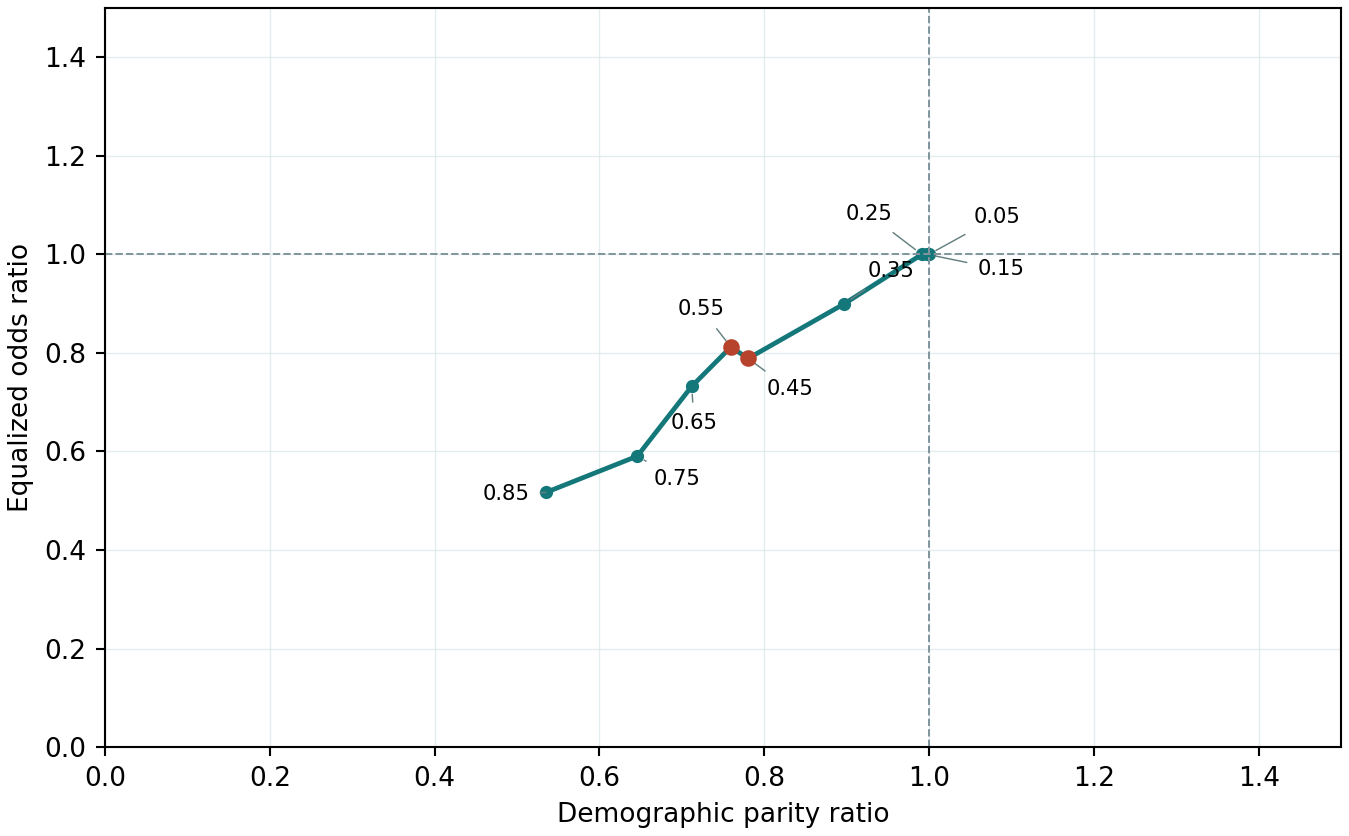

In [9]:
shown = fair.dropna(subset=['DP','EO'])
fig, ax = plt.subplots(figsize=(7.1,4.4),layout='constrained')
ax.plot(shown.DP,shown.EO,'o-',color='#14777a',linewidth=1.8,markersize=4)
ax.scatter(fair.loc[[.45,.55],'DP'],fair.loc[[.45,.55],'EO'],color='#b8432c',s=28,zorder=4)
offsets = [(17,12),(19,-8),(-29,13),(9,10),(7,-14),(-20,12),(-8,-16),(6,-11),(-24,-3)]
for (t,r), offset in zip(shown.iterrows(),offsets):
    ax.annotate(f'{t:.2f}',(r.DP,r.EO),xytext=offset,textcoords='offset points',fontsize=8,
                arrowprops={'arrowstyle':'-','color':'#658080','lw':.55,'shrinkB':3})
ax.axhline(1,color='#81959d',linestyle='--',linewidth=.75)
ax.axvline(1,color='#81959d',linestyle='--',linewidth=.75)
ax.set(xlim=(0,1.5),ylim=(0,1.5),xlabel='Demographic parity ratio',ylabel='Equalized odds ratio')
ax.grid(color='#dae4e8',linewidth=.5,alpha=.7)
ax.set_axisbelow(True)
plt.show()


## References
- Hofmann, H. (1994). Statlog (German Credit Data). UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77
- Original variable codes and error costs: https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.doc
- UCI South German Credit update, for documented limitations of the earlier codebook: https://archive.ics.uci.edu/dataset/573/south+german+credit+update